# 04 Sailkapena: hurrengo orduko ICA kategoria

Hurrengo orduko airearen kalitatea sailkatu nahi dugu: Oso ona, Ona, Erregularra edo Txarra. Enuntziatuak eskatzen dituen hiru algoritmoak (KNN, erabaki-zuhaitza eta Naive Bayes) eta gaian ikusitako Random Forest probatzen ditugu.

Metrikak: accuracy, eta klase bakoitzeko precision, recall eta F1. Klaseak oso desorekatuta daudenez, F1 makroa erabiltzen dugu ereduak alderatzeko (klase guztiek pisu bera dute). "Txarra" klasearen recall-a ere asko begiratzen dugu: alerta bat galtzea alarma faltsu bat baino okerragoa da.

In [1]:
# Liburutegiak
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sys.path.append("../src")
from aurreprozesamendua import ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK, SAILKAPEN_HELBURUA, aurreprozesadorea_sortu

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

# Klaseen ordena, kalitate onenetik txarrenera
KLASEAK = ["Oso ona", "Ona", "Erregularra", "Txarra"]

## 1. Kategoriak

ICA kategoriak Eusko Jaurlaritzaren indize ofizialarenak dira. Estazioaren kategoria bere kutsatzaileen txarrena da, muga hauekin:

| Kutsatzailea | Oso ona | Ona | Erregularra | Txarra |
|---|---|---|---|---|
| PM10 (24 h, µg/m³) | 0-20 | 21-35 | 36-50 | > 50 |
| PM2.5 (24 h, µg/m³) | 0-10 | 11-20 | 21-25 | > 25 |
| NO2 (orduko, µg/m³) | 0-40 | 41-90 | – | – |

In [2]:
entrenamendua = pd.read_csv("../data/prozesatuak/barakaldo_entrenamendua.csv", index_col="data", parse_dates=True)
proba = pd.read_csv("../data/prozesatuak/barakaldo_proba.csv", index_col="data", parse_dates=True)

ALDAGAIAK = ALDAGAI_NUMERIKOAK + ALDAGAI_KATEGORIKOAK
X_entr = entrenamendua[ALDAGAIAK]
X_proba = proba[ALDAGAIAK]
y_entr = entrenamendua[SAILKAPEN_HELBURUA]
y_proba = proba[SAILKAPEN_HELBURUA]

print("Entrenamendua:", X_entr.shape, "| Proba:", X_proba.shape)
pd.DataFrame({"entrenamendua (orduak)": y_entr.value_counts(), "entrenamendua (%)": (y_entr.value_counts(normalize=True) * 100).round(1),
              "proba (orduak)": y_proba.value_counts(), "proba (%)": (y_proba.value_counts(normalize=True) * 100).round(1)}).loc[KLASEAK]

Entrenamendua: (26039, 18) | Proba: (7253, 18)


,entrenamendua (orduak),entrenamendua (%),proba (orduak),proba (%)
ICA_hurrengoa,,,,
Oso ona,14964,57.5,3659,50.4
Ona,9257,35.6,2813,38.8
Erregularra,1422,5.5,653,9.0
Txarra,396,1.5,128,1.8


"Txarra" orduen % 1,5 bakarrik da. Hiperparametroak GridSearchCV-rekin aukeratzen ditugu F1 makroaren arabera. Gaian KFold erabiltzen da, baina denbora-serieetan horrek tranpa egiten du (etorkizuna erabiliko luke iragana iragartzeko); horregatik TimeSeriesSplit erabiltzen dugu: zatiketa bakoitzean iraganarekin entrenatu eta hurrengo aldiarekin balioztatzen du.

In [ ]:
balioztapena = TimeSeriesSplit(n_splits=5)

# Metrikak kalkulatu et zerrenda batean gordetzen dituen funtzioa
emaitzak = []

def ebaluatu(izena, y_benetakoa, y_iragarria, balioztapen_f1=np.nan, denbora=np.nan):
    errenkada = [izena, balioztapen_f1,
                 accuracy_score(y_benetakoa, y_iragarria),
                 precision_score(y_benetakoa, y_iragarria, average="macro", zero_division=0),
                 recall_score(y_benetakoa, y_iragarria, average="macro", zero_division=0),
                 f1_score(y_benetakoa, y_iragarria, average="macro"),
                 recall_score(y_benetakoa, y_iragarria, labels=["Txarra"], average="macro", zero_division=0),
                 precision_score(y_benetakoa, y_iragarria, labels=["Txarra"], average="macro", zero_division=0),
                 denbora]
    emaitzak.append(errenkada)
    print(izena, "-> accuracy:", round(errenkada[2], 3), "| F1 makroa:", round(errenkada[5], 3), "| 'Txarra' recall:", round(errenkada[6], 3))

# Nahasmen-matrize normalizatua marrazteko funtzioa (ehunekoa errenkadako)
def matrizea_marraztu(y_benetakoa, y_iragarria, izenburua, ardatza):
    matrizea = confusion_matrix(y_benetakoa, y_iragarria, labels=KLASEAK, normalize="true")
    ConfusionMatrixDisplay(matrizea, display_labels=KLASEAK).plot(ax=ardatza, cmap="Blues", values_format=".2f", colorbar=False)
    ardatza.set_title(izenburua)

## 2. Erreferentziak

- Klase nagusia: beti "Oso ona".
- Iraunkortasuna: hurrengo orduko kategoria oraingoa izango da. Oso zaila da gainditzea, partikulen ICAk 24 orduko batez bestekoak erabiltzen dituelako eta poliki aldatzen direlako.

In [ ]:
# 2026ko ordu batzuetan uneko kategoria falta da: ohikoena erabiltzen dugu (Oso ona)
print("Uneko kategoriarik gabeko probako orduak:", proba["ICA_estazioa"].isna().sum())
uneko_ica = proba["ICA_estazioa"].fillna("Oso ona")

ebaluatu("Klase nagusia", y_proba, ["Oso ona"] * len(y_proba))
ebaluatu("Iraunkortasuna (uneko ICA)", y_proba, uneko_ica)

Uneko kategoriarik gabeko probako orduak: 1
Klase nagusia -> accuracy: 0.504 | F1 makroa: 0.168 | 'Txarra' recall: 0.0


Iraunkortasuna (uneko ICA) -> accuracy: 0.959 | F1 makroa: 0.95 | 'Txarra' recall: 0.93


In [5]:
# Zenbat aldiz aldatzen den kategoria ordu batetik hurrengora
aldatzen_da = (uneko_ica != y_proba)
print("Hurrengo orduan kategoria aldatzen den orduak:", aldatzen_da.sum(), "/", len(proba),
      "(", round(100 * aldatzen_da.mean(), 1), "% )")

Hurrengo orduan kategoria aldatzen den orduak: 300 / 7253 ( 4.1 % )


Kategoria orduen % 4an bakarrik aldatzen da. Gure ereduek ez dute uneko kategoria jasotzen, beraz iraunkortasunetik gertu geratzea emaitza ona da.

## 3. KNN

Ordu bakoitzerako entrenamenduko K ordu antzekoenak bilatzen ditu eta gehiengoaren kategoria ematen du. Distantziak neurtzen dituenez, datuak estandarizatuta behar ditu (Pipeline-ak egiten du). Hiperparametroak: n_neighbors eta weights.

In [6]:
knn_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", KNeighborsClassifier()),
])
knn_parametroak = {"eredua__n_neighbors": [3, 5, 15, 31, 51, 101],
                   "eredua__weights": ["uniform", "distance"]}

hasiera = time.time()
knn_bilaketa = GridSearchCV(knn_eredua, knn_parametroak, cv=balioztapena, scoring="f1_macro", n_jobs=-1)
knn_bilaketa.fit(X_entr, y_entr)
knn_denbora = time.time() - hasiera

knn_iragarpena = knn_bilaketa.predict(X_proba)
print("Parametro onenak:", knn_bilaketa.best_params_)
print("Balioztapeneko F1 makroa:", round(knn_bilaketa.best_score_, 3))
ebaluatu("KNN", y_proba, knn_iragarpena, knn_bilaketa.best_score_, knn_denbora)

Parametro onenak: {'eredua__n_neighbors': 31, 'eredua__weights': 'uniform'}
Balioztapeneko F1 makroa: 0.717
KNN -> accuracy: 0.838 | F1 makroa: 0.721 | 'Txarra' recall: 0.5


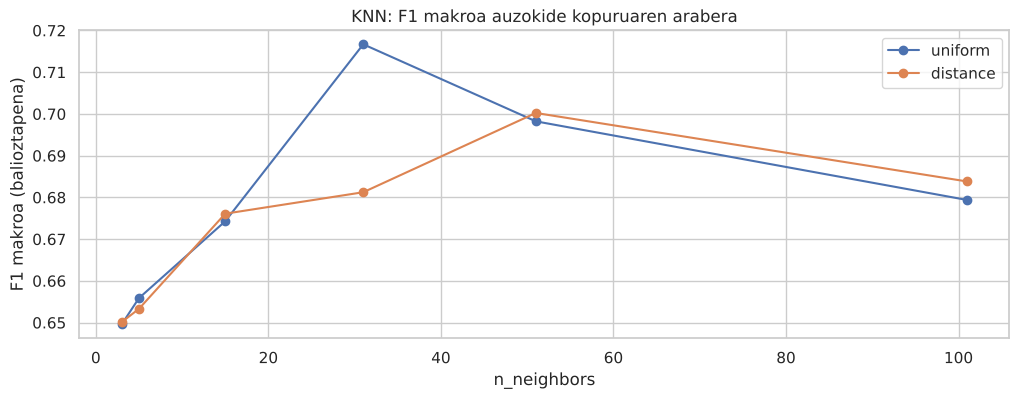

In [7]:
# Balioztapeneko F1a auzokide kopuruaren arabera
knn_taula = pd.DataFrame(knn_bilaketa.cv_results_)
for pisua in ["uniform", "distance"]:
    errenkadak = knn_taula[knn_taula["param_eredua__weights"] == pisua]
    plt.plot(errenkadak["param_eredua__n_neighbors"].astype(int), errenkadak["mean_test_score"], marker="o", label=pisua)
plt.xlabel("n_neighbors")
plt.ylabel("F1 makroa (balioztapena)")
plt.title("KNN: F1 makroa auzokide kopuruaren arabera")
plt.legend()
plt.show()

In [8]:
print(classification_report(y_proba, knn_iragarpena, labels=KLASEAK, digits=3))

              precision    recall  f1-score   support

     Oso ona      0.843     0.964     0.900      3659
         Ona      0.848     0.756     0.800      2813
 Erregularra      0.793     0.547     0.647       653
      Txarra      0.582     0.500     0.538       128

    accuracy                          0.838      7253
   macro avg      0.767     0.692     0.721      7253
weighted avg      0.836     0.838     0.832      7253



## 4. Erabaki-zuhaitza

Zuhaitzak galdera-kate bat egiten du ("Azken 24 orduetako PM10a ≤ 35?") kategoria batera iritsi arte. Hiperparametroak: max_depth, min_samples_leaf eta class_weight.

In [9]:
zuhaitz_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", DecisionTreeClassifier(random_state=42)),
])
zuhaitz_parametroak = {"eredua__max_depth": [3, 4, 6, 8, 12, None],
                       "eredua__min_samples_leaf": [1, 20, 50],
                       "eredua__class_weight": [None, "balanced"]}

hasiera = time.time()
zuhaitz_bilaketa = GridSearchCV(zuhaitz_eredua, zuhaitz_parametroak, cv=balioztapena, scoring="f1_macro", n_jobs=-1)
zuhaitz_bilaketa.fit(X_entr, y_entr)
zuhaitz_denbora = time.time() - hasiera

zuhaitz_iragarpena = zuhaitz_bilaketa.predict(X_proba)
print("Parametro onenak:", zuhaitz_bilaketa.best_params_)
print("Balioztapeneko F1 makroa:", round(zuhaitz_bilaketa.best_score_, 3))
ebaluatu("Erabaki-zuhaitza", y_proba, zuhaitz_iragarpena, zuhaitz_bilaketa.best_score_, zuhaitz_denbora)

Parametro onenak: {'eredua__class_weight': None, 'eredua__max_depth': 4, 'eredua__min_samples_leaf': 1}
Balioztapeneko F1 makroa: 0.923
Erabaki-zuhaitza -> accuracy: 0.948 | F1 makroa: 0.888 | 'Txarra' recall: 1.0


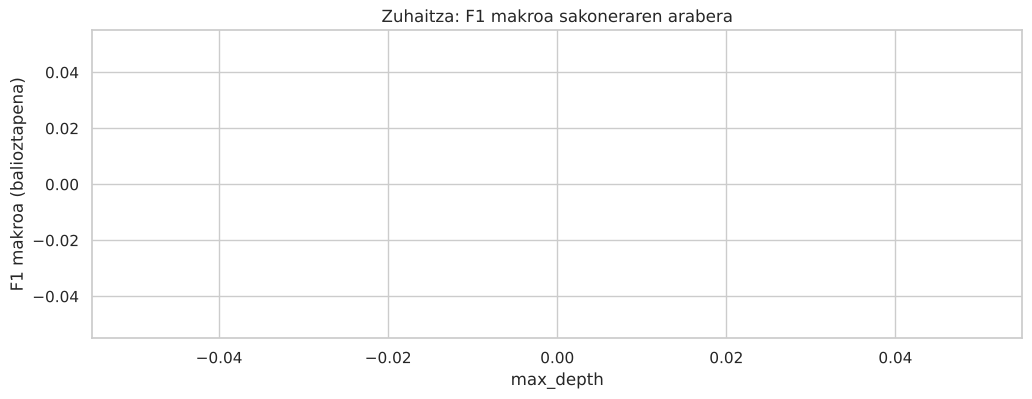

In [10]:
# Sakoneraren eragina (gainerako parametroak beren balio onenean)
zuhaitz_taula = pd.DataFrame(zuhaitz_bilaketa.cv_results_)
onenak = zuhaitz_bilaketa.best_params_
iragazkia = ((zuhaitz_taula["param_eredua__min_samples_leaf"] == onenak["eredua__min_samples_leaf"]) &
             (zuhaitz_taula["param_eredua__class_weight"].astype(str) == str(onenak["eredua__class_weight"])))
sakonerak = zuhaitz_taula.loc[iragazkia, "param_eredua__max_depth"].astype(str)
plt.plot(sakonerak, zuhaitz_taula.loc[iragazkia, "mean_test_score"], marker="o")
plt.xlabel("max_depth")
plt.ylabel("F1 makroa (balioztapena)")
plt.title("Zuhaitza: F1 makroa sakoneraren arabera")
plt.show()

In [11]:
print(classification_report(y_proba, zuhaitz_iragarpena, labels=KLASEAK, digits=3))

              precision    recall  f1-score   support

     Oso ona      0.968     0.972     0.970      3659
         Ona      0.958     0.934     0.946      2813
 Erregularra      0.900     0.865     0.882       653
      Txarra      0.607     1.000     0.755       128

    accuracy                          0.948      7253
   macro avg      0.858     0.943     0.888      7253
weighted avg      0.952     0.948     0.949      7253



### Zer ikasi du zuhaitzak?

Arauak µg/m³-tan irakurtzeko, 3 sakonerako zuhaitz bat entrenatzen dugu datu estandarizatu gabeekin.

In [12]:
# Zuhaitz txikia, aldagai numerikoak jatorrizko unitateetan
X_eskalatu_gabe = X_entr[ALDAGAI_NUMERIKOAK].fillna(X_entr[ALDAGAI_NUMERIKOAK].median())
zuhaitz_txikia = DecisionTreeClassifier(max_depth=3, random_state=42)
zuhaitz_txikia.fit(X_eskalatu_gabe, y_entr)

print(export_text(zuhaitz_txikia, feature_names=ALDAGAI_NUMERIKOAK))

|--- PM10_batez_24h <= 20.93
|   |--- PM25_batez_24h <= 10.85
|   |   |--- NO2 <= 37.50
|   |   |   |--- class: Oso ona
|   |   |--- NO2 >  37.50
|   |   |   |--- class: Ona
|   |--- PM25_batez_24h >  10.85
|   |   |--- PM25_batez_24h <= 20.56
|   |   |   |--- class: Ona
|   |   |--- PM25_batez_24h >  20.56
|   |   |   |--- class: Erregularra
|--- PM10_batez_24h >  20.93
|   |--- PM10_batez_24h <= 35.81
|   |   |--- PM10_batez_24h <= 21.56
|   |   |   |--- class: Ona
|   |   |--- PM10_batez_24h >  21.56
|   |   |   |--- class: Ona
|   |--- PM10_batez_24h >  35.81
|   |   |--- PM10_batez_24h <= 49.15
|   |   |   |--- class: Erregularra
|   |   |--- PM10_batez_24h >  49.15
|   |   |   |--- class: Txarra



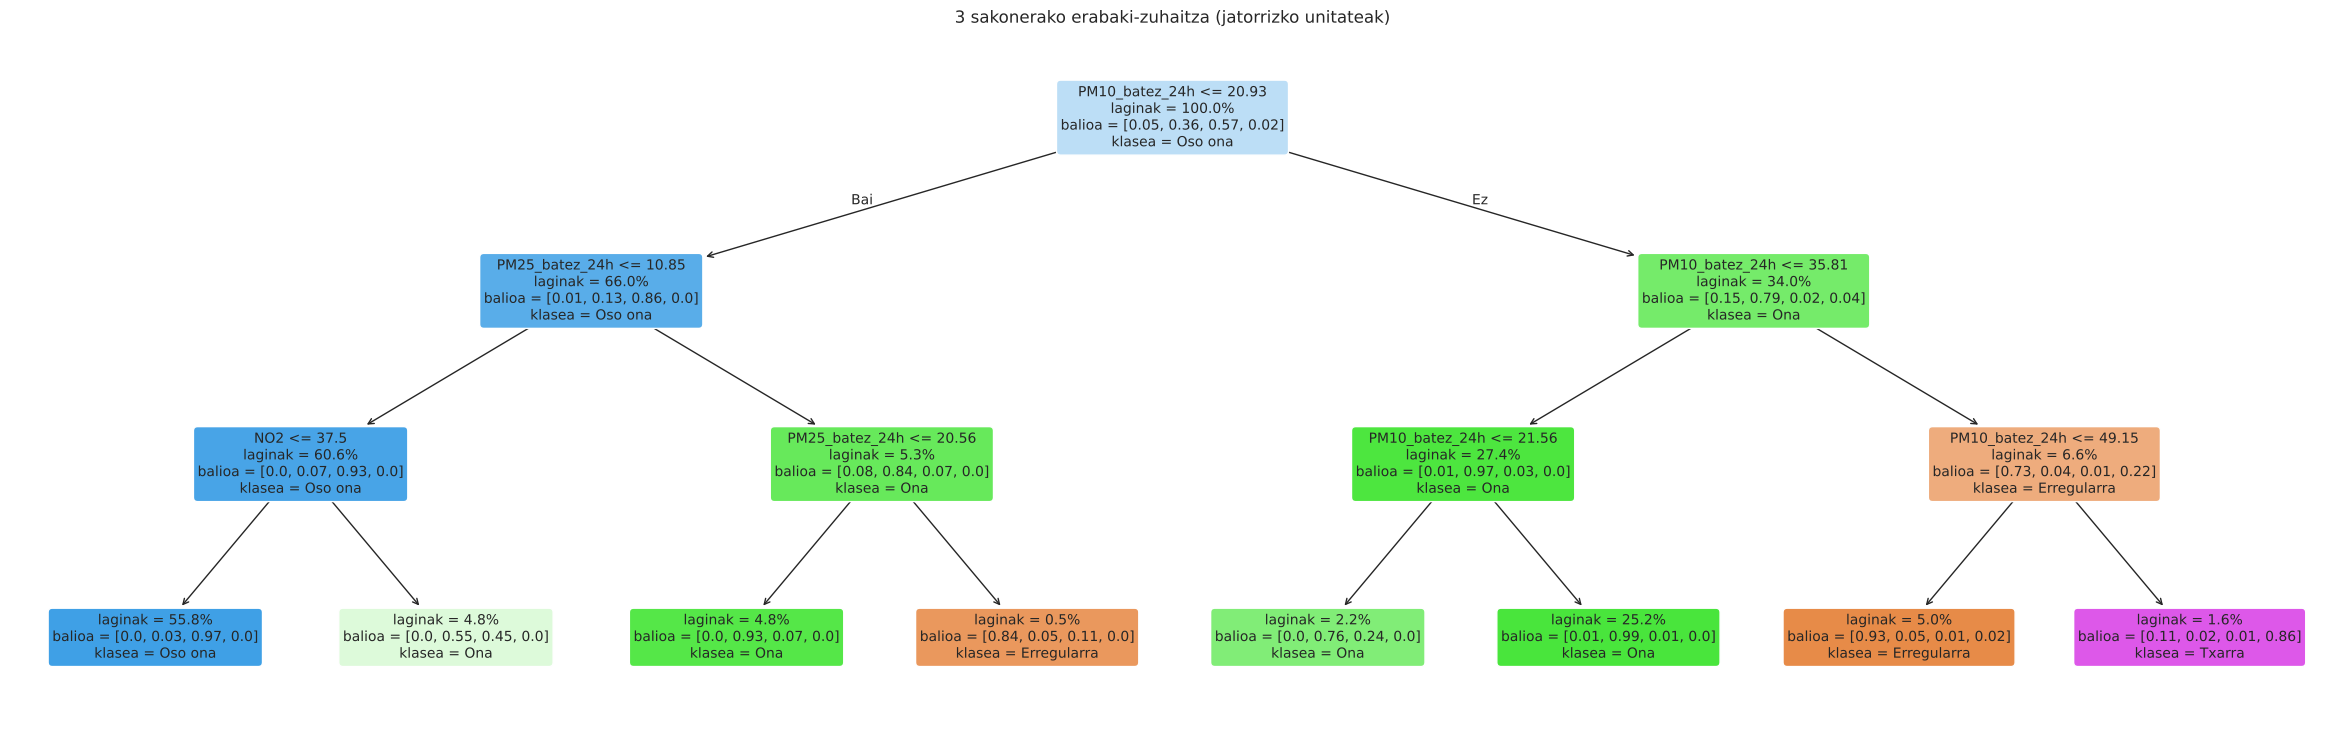

In [13]:
plt.figure(figsize=(30, 9))
plot_tree(zuhaitz_txikia, feature_names=ALDAGAI_NUMERIKOAK, class_names=zuhaitz_txikia.classes_,
          filled=True, rounded=True, fontsize=10, impurity=False, proportion=True, precision=2)
# scikit-learn-ek ingelesez idazten ditu etiketak: euskarara pasatzen ditugu
for testua in plt.gca().texts:
    testua.set_text(testua.get_text().replace("samples", "laginak").replace("value", "balioa")
                    .replace("class", "klasea").replace("True", "Bai").replace("False", "Ez"))
plt.title("3 sakonerako erabaki-zuhaitza (jatorrizko unitateak)")
plt.show()

Zuhaitzak berak aurkitu ditu ICAren muga ofizialak: PM10ean 21, 36 eta 49 inguruan mozten du (ofizialak 20, 35 eta 50), PM2.5ean 11 eta 21ean (10 eta 20) eta NO2an 37,5ean (40). ICA atalaseak dituen arau multzo bat da, eta hori da hain zuzen zuhaitz batek ondo irudikatzen duena. Gainera EDAn ikusitakoa baieztatzen du: Barakaldon partikulek erabakitzen dute kalitatea.

## 5. Naive Bayes

Kategoria bakoitzaren probabilitatea kalkulatzen du, aldagaiak independenteak eta normalak direla suposatuz (GaussianNB). Hiperparametroa: var_smoothing.

In [14]:
nb_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", GaussianNB()),
])
nb_parametroak = {"eredua__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-2, 1e-1, 0.5]}

hasiera = time.time()
nb_bilaketa = GridSearchCV(nb_eredua, nb_parametroak, cv=balioztapena, scoring="f1_macro", n_jobs=-1)
nb_bilaketa.fit(X_entr, y_entr)
nb_denbora = time.time() - hasiera

nb_iragarpena = nb_bilaketa.predict(X_proba)
print("Parametro onenak:", nb_bilaketa.best_params_)
print("Balioztapeneko F1 makroa:", round(nb_bilaketa.best_score_, 3))
ebaluatu("Naive Bayes", y_proba, nb_iragarpena, nb_bilaketa.best_score_, nb_denbora)

Parametro onenak: {'eredua__var_smoothing': 0.5}
Balioztapeneko F1 makroa: 0.601
Naive Bayes -> accuracy: 0.746 | F1 makroa: 0.645 | 'Txarra' recall: 0.445


In [15]:
print(classification_report(y_proba, nb_iragarpena, labels=KLASEAK, digits=3))

              precision    recall  f1-score   support

     Oso ona      0.745     0.937     0.831      3659
         Ona      0.781     0.543     0.641      2813
 Erregularra      0.682     0.606     0.642       653
      Txarra      0.487     0.445     0.465       128

    accuracy                          0.746      7253
   macro avg      0.674     0.633     0.645      7253
weighted avg      0.749     0.746     0.733      7253



Naive Bayes okerragoa da, bere bi suposizioak ez direlako betetzen: aldagaiak oso lotuta daude (NO2, aurreko orduko NO2a, 24 orduko batez bestekoa...) eta kutsatzaileak ez dira normalak.

## 6. Random Forest

Konparazioa osatzeko, gaian ikusitako beste sailkatzaile bat: Random Forest (200 zuhaitz).

In [16]:
rf_eredua = Pipeline([
    ("aurreprozesamendua", aurreprozesadorea_sortu(ALDAGAI_NUMERIKOAK, ALDAGAI_KATEGORIKOAK)),
    ("eredua", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
])
rf_parametroak = {"eredua__max_depth": [4, 8, None],
                  "eredua__min_samples_leaf": [1, 20],
                  "eredua__class_weight": [None, "balanced"]}

hasiera = time.time()
rf_bilaketa = GridSearchCV(rf_eredua, rf_parametroak, cv=balioztapena, scoring="f1_macro")
rf_bilaketa.fit(X_entr, y_entr)
rf_denbora = time.time() - hasiera

rf_iragarpena = rf_bilaketa.predict(X_proba)
print("Parametro onenak:", rf_bilaketa.best_params_)
print("Balioztapeneko F1 makroa:", round(rf_bilaketa.best_score_, 3))
ebaluatu("Random Forest", y_proba, rf_iragarpena, rf_bilaketa.best_score_, rf_denbora)

Parametro onenak: {'eredua__class_weight': 'balanced', 'eredua__max_depth': None, 'eredua__min_samples_leaf': 1}
Balioztapeneko F1 makroa: 0.884
Random Forest -> accuracy: 0.951 | F1 makroa: 0.896 | 'Txarra' recall: 0.906


Random Forestek F1 makro apur bat hobea du proban (0,90, zuhaitzaren 0,89), baina okerragoa balioztapenean, "Txarra" ordu gutxiago detektatzen ditu (% 91, zuhaitzaren % 100) eta 5 aldiz motelagoa da.

## 7. Lau ereduen alderaketa

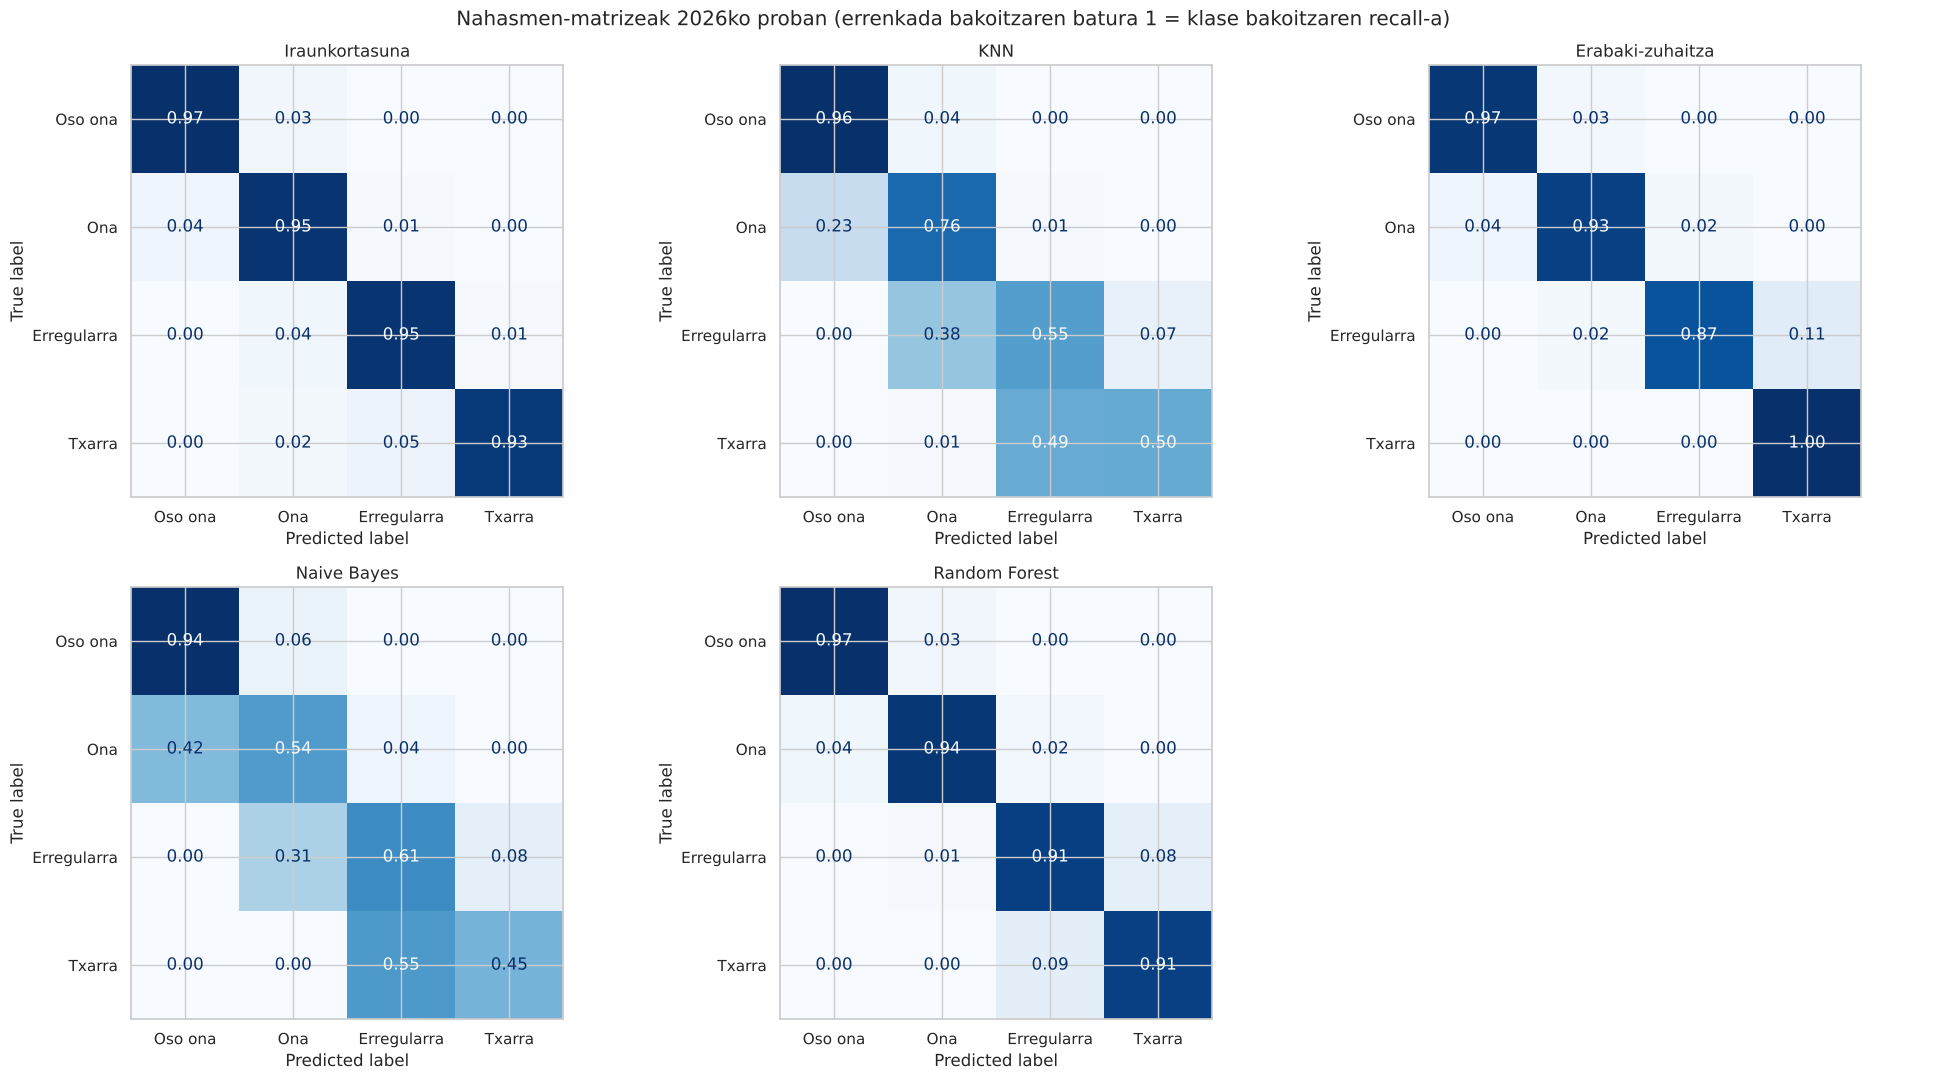

In [17]:
fig, ardatzak = plt.subplots(2, 3, figsize=(20, 11))
matrizea_marraztu(y_proba, uneko_ica, "Iraunkortasuna", ardatzak[0, 0])
matrizea_marraztu(y_proba, knn_iragarpena, "KNN", ardatzak[0, 1])
matrizea_marraztu(y_proba, zuhaitz_iragarpena, "Erabaki-zuhaitza", ardatzak[0, 2])
matrizea_marraztu(y_proba, nb_iragarpena, "Naive Bayes", ardatzak[1, 0])
matrizea_marraztu(y_proba, rf_iragarpena, "Random Forest", ardatzak[1, 1])
ardatzak[1, 2].axis("off")
plt.suptitle("Nahasmen-matrizeak 2026ko proban (errenkada bakoitzaren batura 1 = klase bakoitzaren recall-a)")
plt.tight_layout()
plt.show()

In [ ]:
taula = pd.DataFrame(emaitzak, columns=["eredua", "balioztapen F1 makroa", "accuracy", "precision makroa", "recall makroa", "F1 makroa", "Txarra recall","Txarra precision", "bilaketa-denbora (s)"])
taula.round(3)

,eredua,balioztapen F1 makroa,accuracy,precision makroa,recall makroa,F1 makroa,Txarra recall,Txarra precision,bilaketa-denbora (s)
0,Klase nagusia,NaN,0.504,0.126,0.250,0.168,0.000,0.000,NaN
1,Iraunkortasuna (uneko ICA),NaN,0.959,0.949,0.950,0.950,0.930,0.930,NaN
2,KNN,0.717,0.838,0.767,0.692,0.721,0.500,0.582,12.558
3,Erabaki-zuhaitza,0.923,0.948,0.858,0.943,0.888,1.000,0.607,12.869
4,Naive Bayes,0.601,0.746,0.674,0.633,0.645,0.445,0.487,1.295
5,Random Forest,0.884,0.951,0.870,0.931,0.896,0.906,0.667,64.001


#### Alderaketa

| Eredua | F1 makroa (proba) | "Txarra" recall | Iruzkina |
|---|---|---|---|
| Erabaki-zuhaitza | 0,89 | 1,00 | Onena balioztapenean (0,92); interpretagarria |
| Random Forest | 0,90 | 0,91 | Antzekoa, baina alerta gehiago galtzen ditu eta kutxa beltza da |
| KNN | 0,72 | 0,50 | "Ona" eta "Erregularra" nahasten ditu; 65 zutabeetan distantziak ez dira esanguratsuak |
| Naive Bayes | 0,65 | 0,45 | Azkarrena, baina suposizioak ez dira betetzen |

Inork ez du iraunkortasuna (0,95) gainditzen uneko kategoria jakin gabe, baina zuhaitzak "Txarra" ordu gehiago detektatzen ditu (128tik 128, iraunkortasunak % 93).

## 8. Arriskuak

| Arriskua | Neurria |
|---|---|
| Klase desorekatuak ("Txarra" % 1,5) | F1 makroa erabili eta "Txarra" recall-a zaindu |
| Accuracy engainagarria | Beti klase nagusiarekin eta iraunkortasunarekin alderatu |
| Etiketa zalantzagarriak (2023ko udan ICA PM10 gabe) | Dokumentatuta; 2026an PM10 ia osoa dago |
| Alarma faltsuak | "Txarra" precision 0,61: huts egiten duenean, benetako ordua ia beti "Erregularra" da |

## 9. Ondorioak

Erabaki-zuhaitza aukeratzen dugu (4 sakonera):

- "Txarra" ordu guztiak detektatzen ditu 2026an (128tik 128). Random Forestek 12 galtzen ditu eta iraunkortasunak 9; azken horiek episodioen lehen orduak dira, abisua behar den unea, eta zuhaitzak denak harrapatzen ditu.
- Balioztapenean da onena (F1 makroa 0,923; Random Forest 0,884). Proban Random Forest apur bat gorago dago (0,896 / 0,888), baina eredua balioztapenarekin aukeratzen dugu, ez 2026ko emaitzarekin.
- Bere 83 alarma faltsuetatik 75 ordu Erregularrak dira: huts egiten duenean ere airea ez zen ona.
- Bere F1 makroa Random Forestaren oso gertu dago, baina askoz sinpleagoa da: 16 hosto, 200 zuhaitzen ordez.
- Interpretagarria da: bere arauak ICAren muga ofizialak dira, eta edozein teknikariri azal dakizkioke.
- Oso arina da Jetson Nanorako (bilaketa 13 s, Random Forestarena 64 s).

In [19]:
joblib.dump(zuhaitz_bilaketa.best_estimator_, "../ereduak/sailkapen_onena_zuhaitza.joblib")
taula.to_csv("../docs/emaitzak_sailkapena.csv", index=False)
print("Gordeta: ereduak/sailkapen_onena_zuhaitza.joblib eta docs/emaitzak_sailkapena.csv")
print("Sarrerako aldagaiak: PIAko Pipeline-aren berberak (ereduak/sarrera_aldagaiak.joblib)")

Gordeta: ereduak/sailkapen_onena_zuhaitza.joblib eta docs/emaitzak_sailkapena.csv
Sarrerako aldagaiak: PIAko Pipeline-aren berberak (ereduak/sarrera_aldagaiak.joblib)
